# 2. Interacting with Web APIs
Problem Statement: Analyzing Weather Data from OpenWeatherMap API<br>
Dataset: Weather data retrieved from OpenWeatherMap API<br>
Description: The goal is to interact with the OpenWeatherMap API to retrieve weather data
for a specific location and perform data modeling and visualization to analyze weather
patterns over time.<br>
Tasks to Perform:
1. Register and obtain API key from OpenWeatherMap.<br>
2. Interact with the OpenWeatherMap API using the API key to retrieve weather data for
a specific location.<br>
3. Extract relevant weather attributes such as temperature, humidity, wind speed, and
precipitation from the API response.<br>
4. Clean and preprocess the retrieved data, handling missing values or inconsistent
formats.<br>
5. Perform data modeling to analyze weather patterns, such as calculating average
temperature, maximum/minimum values, or trends over time.<br>
6. Visualize the weather data using appropriate plots, such as line charts, bar plots, or
scatter plots, to represent temperature changes, precipitation levels, or wind speed
variations.<br>
7. Apply data aggregation techniques to summarize weather statistics by specific time
periods (e.g., daily, monthly, seasonal).<br>
8. Incorporate geographical information, if available, to create maps or geospatial
visualizations representing weather patterns across different locations.<br>
9. Explore and visualize relationships between weather attributes, such as temperature
and humidity, using correlation plots or heatmaps.<br>

In [1]:
!python -m pip install requests

In [7]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
# 1. SET API DETAILS
key = "700e145e0cb51245816c9c9ea02815a4"
cities = ["Pune", "Mumbai", "Delhi"]

records = []


In [24]:
# 2. GET WEATHER DATA
for city in cities:

    url = "https://api.openweathermap.org/data/2.5/forecast"

    data = requests.get(url, params={
        "q": city + ",IN",
        "appid": key,
        "units": "metric"
    }).json()

    if "list" not in data:
        print("Error:", city, data.get("message"))
        continue

    lat = data["city"]["coord"]["lat"]
    lon = data["city"]["coord"]["lon"]

    # 3. EXTRACT WEATHER DATA
    for x in data["list"]:
        records.append({
            "City": city,
            "Date": x["dt_txt"],
            "Temperature": x["main"]["temp"],
            "Humidity": x["main"]["humidity"],
            "Wind": x["wind"]["speed"],
            "Rain": x.get("rain", {}).get("3h", 0) + x.get("snow", {}).get("3h", 0),
            "Latitude": lat,
            "Longitude": lon
        })


In [25]:
# 4. CREATE DATAFRAME
df = pd.DataFrame(records)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())

   City                Date  Temperature  Humidity  Wind  Rain  Latitude  \
0  Pune 2026-11-01 12:00:00        26.46        51  2.87  1.33   18.5196   
1  Pune 2026-11-01 15:00:00        26.64        58  0.82  0.00   18.5196   
2  Pune 2026-11-01 18:00:00        27.07        67  0.66  0.23   18.5196   
3  Pune 2026-11-01 21:00:00        25.94        79  1.42  0.64   18.5196   
4  Pune 2026-11-02 00:00:00        25.63        85  2.62  2.36   18.5196   

   Longitude  
0    73.8553  
1    73.8553  
2    73.8553  
3    73.8553  
4    73.8553  

Missing Values:
City           0
Date           0
Temperature    0
Humidity       0
Wind           0
Rain           0
Latitude       0
Longitude      0
dtype: int64


In [26]:
# 6. ANALYZE WEATHER DATA
print("\nAverage Temperature:")
print(df.groupby("City")["Temperature"].mean())

print("\nMaximum Temperature:")
print(df.groupby("City")["Temperature"].max())

print("\nMinimum Temperature:")
print(df.groupby("City")["Temperature"].min())



Average Temperature:
City
Delhi     27.58775
Mumbai    29.07725
Pune      26.70200
Name: Temperature, dtype: float64

Maximum Temperature:
City
Delhi     33.67
Mumbai    31.48
Pune      31.77
Name: Temperature, dtype: float64

Minimum Temperature:
City
Delhi     19.51
Mumbai    27.22
Pune      22.50
Name: Temperature, dtype: float64


In [27]:
# 7. DATA AGGREGATION
df["Day"] = df["Date"].dt.date
df["Month"] = df["Date"].dt.month

print("\nDaily Weather:")
daily = df.groupby(["City", "Day"])[
    ["Temperature", "Humidity", "Wind", "Rain"]
].mean()

print(daily)

print("\nMonthly Temperature:")
print(df.groupby(["City", "Month"])["Temperature"].mean())


Daily Weather:
                   Temperature  Humidity     Wind     Rain
City   Day                                                
Delhi  2026-11-01     25.29000    44.625  1.42000  0.00000
       2026-11-02     24.96250    30.250  1.19250  0.00000
       2026-11-03     27.87625    21.625  1.67125  0.00000
       2026-11-04     28.82875    20.375  1.63500  0.00000
       2026-11-05     29.05875    18.500  1.81625  0.00000
       2026-11-06     29.13500    18.000  2.46250  0.00000
Mumbai 2026-11-01     29.38000    68.000  4.06500  0.03250
       2026-11-02     29.43125    67.000  2.28125  0.00000
       2026-11-03     28.28750    72.125  2.40625  0.11000
       2026-11-04     28.71250    69.750  2.63875  0.00000
       2026-11-05     29.50250    65.250  3.54250  0.00000
       2026-11-06     29.52500    61.000  2.57500  0.00000
Pune   2026-11-01     26.52750    63.750  1.44250  0.55000
       2026-11-02     26.82875    72.750  2.04750  1.02625
       2026-11-03     26.25000    68.125

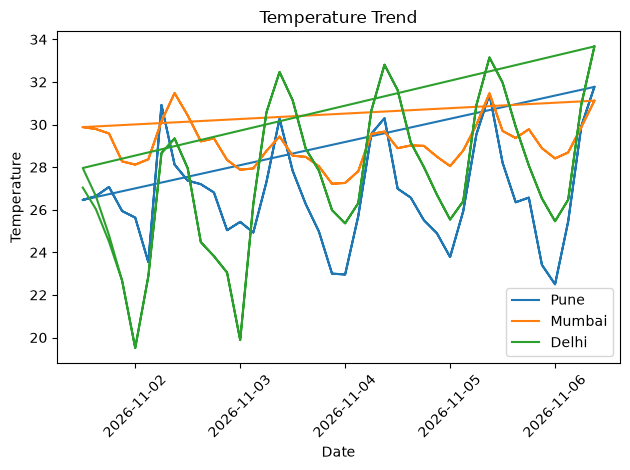

In [33]:
# 8. LINE CHART - TEMPERATURE
for city in cities:
    d = df[df["City"] == city]
    if not d.empty:
        plt.plot(d["Date"], d["Temperature"], label=city)

plt.title("Temperature Trend")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

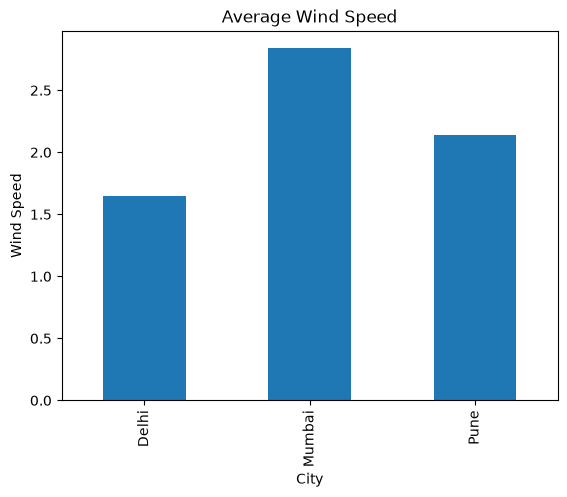

In [29]:
# 9. BAR CHART - WIND SPEED
df.groupby("City")["Wind"].mean().plot(kind="bar")
plt.title("Average Wind Speed")
plt.ylabel("Wind Speed")
plt.show()


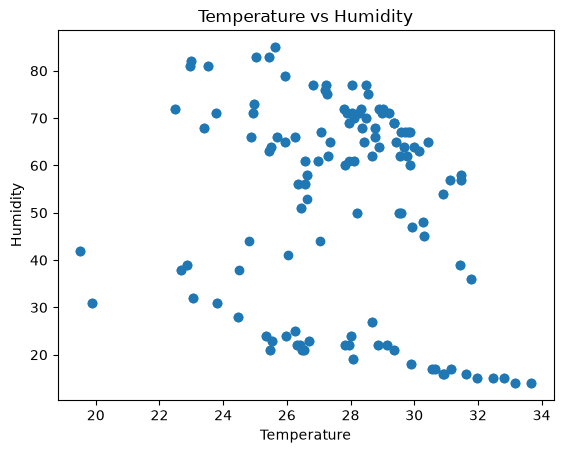

In [30]:

# 10. SCATTER PLOT - TEMPERATURE VS HUMIDITY
plt.scatter(df["Temperature"], df["Humidity"])
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.title("Temperature vs Humidity")
plt.show()

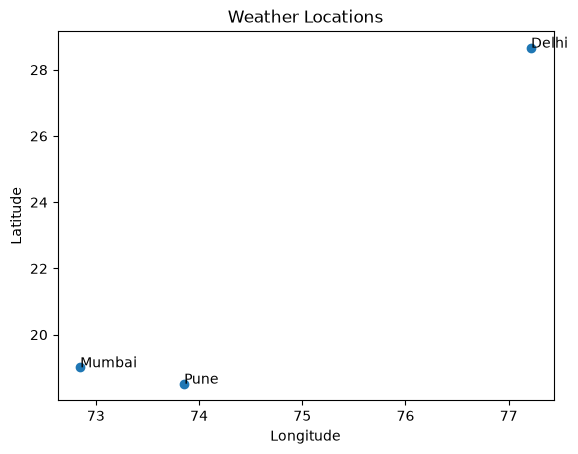

In [31]:
# 11. GEOGRAPHICAL VISUALIZATION
loc = df.groupby("City")[["Latitude", "Longitude"]].first()

plt.scatter(loc["Longitude"], loc["Latitude"])

for city, row in loc.iterrows():
    plt.text(row["Longitude"], row["Latitude"], city)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Weather Locations")
plt.show()


Weather Correlation:
             Temperature  Humidity      Wind      Rain
Temperature     1.000000 -0.215156  0.484020 -0.185152
Humidity       -0.215156  1.000000  0.155626  0.316928
Wind            0.484020  0.155626  1.000000 -0.123833
Rain           -0.185152  0.316928 -0.123833  1.000000


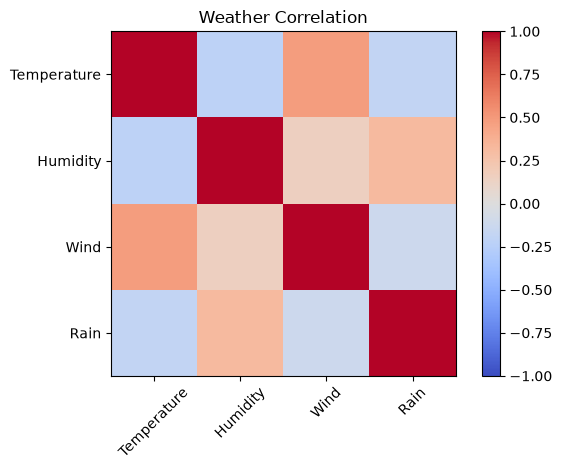

In [32]:
# 12. CORRELATION AND HEATMAP
corr = df[["Temperature", "Humidity", "Wind", "Rain"]].corr()

print("\nWeather Correlation:")
print(corr)

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(4), corr.columns, rotation=45)
plt.yticks(range(4), corr.columns)
plt.title("Weather Correlation")
plt.tight_layout()
plt.show()